
# Baseline Model Training

## 1. Objective

The objective of this notebook is to establish baseline performance for predicting restaurant weighted ratings using supervised machine learning regression algorithms.

Multiple regression models will be trained and compared using the prepared training dataset.

The baseline results will serve as a reference for evaluating improvements from advanced models, feature engineering, and hyperparameter tuning.

## 2. Problem Statement

This project focuses on predicting the weighted rating of a restaurant using available restaurant-related features, including:

- Cuisine information
- Restaurant location
- Menu characteristics
- Pricing information
- Geographical features

**Target Variable:** `weighted_rating`

**Problem Type:** Supervised Machine Learning – Regression

## 3. Evaluation Metrics

The models will be evaluated using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R-squared (R²)

## 4. Models

The following algorithms will be considered:

1. Dummy Regressor
2. Linear Regression
3. Ridge Regression
4. Random Forest Regressor
5. Gradient Boosting Regressor
6. CatBoost Regressor

## 5. Expected Outcome

The objective is to identify a suitable baseline model, understand the performance of different regression algorithms, and establish a benchmark for subsequent model improvement and deployment.


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

FIGURES_DIR = "outputs/baseline/figures"
TABLES_DIR = "outputs/baseline/tables"
MODELS_DIR = "outputs/baseline/models"

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(TABLES_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

print("Libraries imported successfully.")
print("Output directories created successfully.")

Libraries imported successfully.
Output directories created successfully.


In [3]:
DATA_DIR = "data/processed"

X_train_processed = pd.read_csv(
    os.path.join(DATA_DIR, "X_train_processed.csv")
)
X_test_processed = pd.read_csv(
    os.path.join(DATA_DIR, "X_test_processed.csv")
)

X_train_scaled = pd.read_csv(
    os.path.join(DATA_DIR, "X_train_scaled.csv")
)
X_test_scaled = pd.read_csv(
    os.path.join(DATA_DIR, "X_test_scaled.csv")
)

X_train_cat = pd.read_csv(
    os.path.join(DATA_DIR, "X_train_catboost.csv")
)
X_test_cat = pd.read_csv(
    os.path.join(DATA_DIR, "X_test_catboost.csv")
)

y_train = pd.read_csv(
    os.path.join(DATA_DIR, "y_train.csv")
).squeeze("columns")

y_test = pd.read_csv(
    os.path.join(DATA_DIR, "y_test.csv")
).squeeze("columns")

print("All datasets loaded successfully.")
print("Processed:", X_train_processed.shape, X_test_processed.shape)
print("Scaled:", X_train_scaled.shape, X_test_scaled.shape)
print("CatBoost:", X_train_cat.shape, X_test_cat.shape)
print("Targets:", y_train.shape, y_test.shape)

All datasets loaded successfully.
Processed: (53574, 263) (13394, 263)
Scaled: (53574, 263) (13394, 263)
CatBoost: (53574, 124) (13394, 124)
Targets: (53574,) (13394,)


In [4]:
print("TRAINING DATA")
print("Missing feature values:", X_train_processed.isna().sum().sum())
print("Missing target values:", y_train.isna().sum())

print("\nTESTING DATA")
print("Missing feature values:", X_test_processed.isna().sum().sum())
print("Missing target values:", y_test.isna().sum())

print("\nFEATURE CONSISTENCY")
print("Processed columns match:",
      X_train_processed.columns.equals(X_test_processed.columns))
print("Scaled columns match:",
      X_train_scaled.columns.equals(X_test_scaled.columns))
print("CatBoost columns match:",
      X_train_cat.columns.equals(X_test_cat.columns))

print("\nTARGET DISTRIBUTION")
print(y_train.describe())

TRAINING DATA
Missing feature values: 0
Missing target values: 0

TESTING DATA
Missing feature values: 0
Missing target values: 0

FEATURE CONSISTENCY
Processed columns match: True
Scaled columns match: True
CatBoost columns match: True

TARGET DISTRIBUTION
count    53574.000000
mean         3.937199
std          0.169883
min          2.446742
25%          3.845135
50%          3.928469
75%          4.028469
max          4.735694
Name: weighted_rating, dtype: float64


In [5]:
suspicious_keywords = [
    "rating", "review", "score", "weighted"
]

suspicious_features = [
    col for col in X_train_cat.columns
    if any(keyword in col.lower() for keyword in suspicious_keywords)
]

print("Potentially suspicious features:")
for feature in suspicious_features:
    print(feature)

print("\nTotal:", len(suspicious_features))

Potentially suspicious features:

Total: 0


In [6]:
X_train_base, X_val_base, y_train_base, y_val_base = train_test_split(
    X_train_processed,
    y_train,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training set:", X_train_base.shape)
print("Validation set:", X_val_base.shape)
print("Training target:", y_train_base.shape)
print("Validation target:", y_val_base.shape)

Training set: (42859, 263)
Validation set: (10715, 263)
Training target: (42859,)
Validation target: (10715,)


In [7]:
def evaluate_model(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

baseline_results = []

print("Evaluation function defined successfully.")

Evaluation function defined successfully.


In [8]:
dummy_model = DummyRegressor(strategy="mean")

dummy_model.fit(X_train_base, y_train_base)

dummy_val_predictions = dummy_model.predict(X_val_base)

dummy_results = evaluate_model(
    "Dummy Regressor",
    y_val_base,
    dummy_val_predictions
)

baseline_results.append(dummy_results)

print("Dummy Regressor trained successfully.")
print(dummy_results)

Dummy Regressor trained successfully.
{'Model': 'Dummy Regressor', 'MAE': 0.12508828759788007, 'RMSE': np.float64(0.1690505637503271), 'R2': -0.0006253688857336126}


In [9]:
X_train_linear = X_train_scaled.loc[X_train_base.index]
X_val_linear = X_train_scaled.loc[X_val_base.index]

linear_model = LinearRegression()

linear_model.fit(X_train_linear, y_train_base)

linear_val_predictions = linear_model.predict(X_val_linear)

linear_results = evaluate_model(
    "Linear Regression",
    y_val_base,
    linear_val_predictions
)

baseline_results.append(linear_results)

print("Linear Regression trained successfully.")
print(linear_results)

Linear Regression trained successfully.
{'Model': 'Linear Regression', 'MAE': 0.10483025923308786, 'RMSE': np.float64(0.14161871784405347), 'R2': 0.29776967685887656}


In [10]:
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_linear, y_train_base)

ridge_val_predictions = ridge_model.predict(X_val_linear)

ridge_results = evaluate_model(
    "Ridge Regression",
    y_val_base,
    ridge_val_predictions
)

baseline_results.append(ridge_results)

print("Ridge Regression trained successfully.")
print(ridge_results)

Ridge Regression trained successfully.
{'Model': 'Ridge Regression', 'MAE': 0.1048302349961626, 'RMSE': np.float64(0.14161878037205472), 'R2': 0.29776905675626775}


In [11]:
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

random_forest_model.fit(X_train_base, y_train_base)

rf_val_predictions = random_forest_model.predict(X_val_base)

rf_results = evaluate_model(
    "Random Forest",
    y_val_base,
    rf_val_predictions
)

baseline_results.append(rf_results)

print("Random Forest trained successfully.")
print(rf_results)

Random Forest trained successfully.
{'Model': 'Random Forest', 'MAE': 0.0998007086803476, 'RMSE': np.float64(0.13503196353582161), 'R2': 0.36157273141490076}


In [12]:
gradient_boosting_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=RANDOM_STATE
)

gradient_boosting_model.fit(X_train_base, y_train_base)

gb_val_predictions = gradient_boosting_model.predict(X_val_base)

gb_results = evaluate_model(
    "Gradient Boosting",
    y_val_base,
    gb_val_predictions
)

baseline_results.append(gb_results)

print("Gradient Boosting trained successfully.")
print(gb_results)

Gradient Boosting trained successfully.
{'Model': 'Gradient Boosting', 'MAE': 0.10361729644106699, 'RMSE': np.float64(0.14087703740531948), 'R2': 0.30510580678199595}


In [13]:
catboost_config = joblib.load(
    os.path.join(DATA_DIR, "catboost_config.joblib")
)

cat_cols = catboost_config["categorical_features"]

X_train_cat_base = X_train_cat.loc[X_train_base.index].copy()
X_val_cat = X_train_cat.loc[X_val_base.index].copy()

print("CatBoost data prepared successfully.")
print("Categorical features:", cat_cols)
print("Training shape:", X_train_cat_base.shape)
print("Validation shape:", X_val_cat.shape)

CatBoost data prepared successfully.
Categorical features: ['cuisine', 'locality', 'city', 'geocoding_status', 'state', 'geographic_state_validation_status', 'dominant_menu_category']
Training shape: (42859, 124)
Validation shape: (10715, 124)


In [14]:
catboost_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="RMSE",
    eval_metric="RMSE",
    random_seed=RANDOM_STATE,
    verbose=100,
    early_stopping_rounds=50
)

catboost_model.fit(
    X_train_cat_base,
    y_train_base,
    cat_features=cat_cols,
    eval_set=(X_val_cat, y_val_base),
    use_best_model=True
)

catboost_val_predictions = catboost_model.predict(X_val_cat)

catboost_results = evaluate_model(
    "CatBoost",
    y_val_base,
    catboost_val_predictions
)

baseline_results.append(catboost_results)

print("\nCatBoost trained successfully.")
print("Best iteration:", catboost_model.get_best_iteration())
print(catboost_results)

0:	learn: 0.1681889	test: 0.1671097	best: 0.1671097 (0)	total: 138ms	remaining: 1m 8s
100:	learn: 0.1395526	test: 0.1377450	best: 0.1377450 (100)	total: 5.13s	remaining: 20.3s
200:	learn: 0.1370908	test: 0.1363527	best: 0.1363527 (200)	total: 9.96s	remaining: 14.8s
300:	learn: 0.1348789	test: 0.1354677	best: 0.1354677 (300)	total: 14.7s	remaining: 9.72s
400:	learn: 0.1329146	test: 0.1348564	best: 0.1348564 (400)	total: 19.4s	remaining: 4.8s
499:	learn: 0.1312796	test: 0.1344818	best: 0.1344818 (499)	total: 24.1s	remaining: 0us

bestTest = 0.1344818388
bestIteration = 499


CatBoost trained successfully.
Best iteration: 499
{'Model': 'CatBoost', 'MAE': 0.09969436665990046, 'RMSE': np.float64(0.13448183781772918), 'R2': 0.3667640923011326}


In [15]:
baseline_results_df = pd.DataFrame(baseline_results)

baseline_results_df = baseline_results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

display(
    baseline_results_df.style
    .format({
        "MAE": "{:.5f}",
        "RMSE": "{:.5f}",
        "R2": "{:.5f}"
    })
    .highlight_min(subset=["MAE", "RMSE"], color="lightgreen")
    .highlight_max(subset=["R2"], color="lightgreen")
    .set_caption("Baseline Model Performance Comparison")
)

baseline_results_df.to_csv(
    os.path.join(TABLES_DIR, "baseline_model_comparison.csv"),
    index=False
)

print("\nTable saved to:", os.path.join(
    TABLES_DIR, "baseline_model_comparison.csv"
))

,Model,MAE,RMSE,R2
0,CatBoost,0.09969,0.13448,0.36676
1,Random Forest,0.09980,0.13503,0.36157
2,Gradient Boosting,0.10362,0.14088,0.30511
3,Linear Regression,0.10483,0.14162,0.29777
4,Ridge Regression,0.10483,0.14162,0.29777
5,Dummy Regressor,0.12509,0.16905,-0.00063



Table saved to: outputs/baseline/tables\baseline_model_comparison.csv


In [16]:
baseline_models = {
    "dummy_regressor": dummy_model,
    "linear_regression": linear_model,
    "ridge_regression": ridge_model,
    "random_forest": random_forest_model,
    "gradient_boosting": gradient_boosting_model
}

for model_name, model in baseline_models.items():
    joblib.dump(
        model,
        os.path.join(MODELS_DIR, f"{model_name}.joblib")
    )

catboost_model.save_model(
    os.path.join(MODELS_DIR, "catboost_model.cbm")
)

print("All baseline models saved successfully.")

for filename in os.listdir(MODELS_DIR):
    print(filename)

All baseline models saved successfully.
catboost_model.cbm
dummy_regressor.joblib
gradient_boosting.joblib
linear_regression.joblib
random_forest.joblib
ridge_regression.joblib


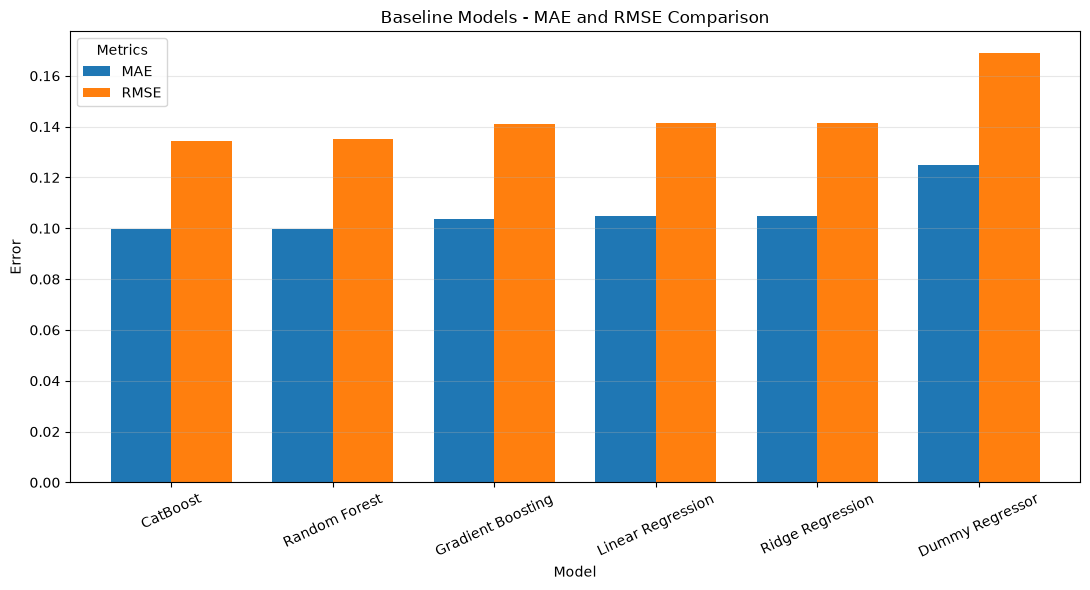

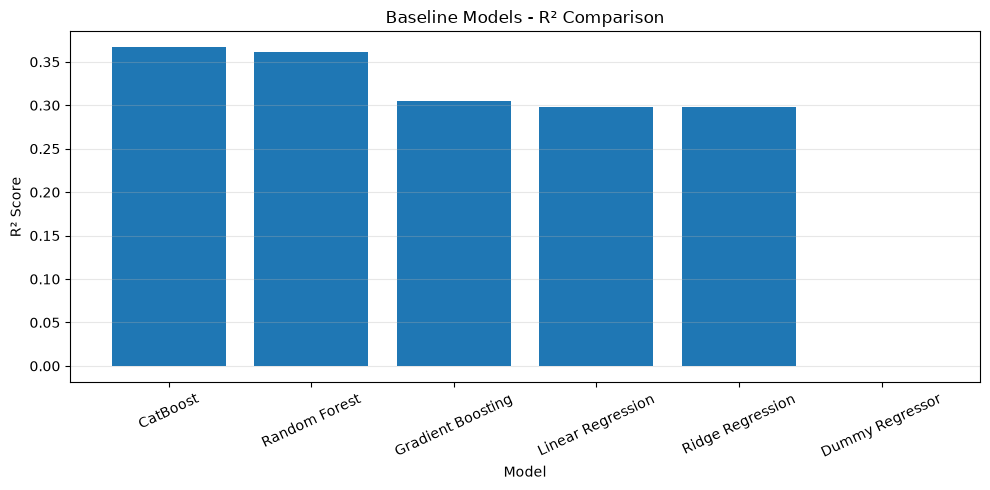

Both comparison charts saved successfully.


In [17]:
fig, ax = plt.subplots(figsize=(11, 6))

plot_data = baseline_results_df.set_index("Model")[["MAE", "RMSE"]]

plot_data.plot(
    kind="bar",
    ax=ax,
    width=0.75
)

ax.set_title("Baseline Models - MAE and RMSE Comparison")
ax.set_ylabel("Error")
ax.set_xlabel("Model")
ax.tick_params(axis="x", rotation=25)
ax.legend(title="Metrics")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(FIGURES_DIR, "baseline_error_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    baseline_results_df["Model"],
    baseline_results_df["R2"]
)

ax.set_title("Baseline Models - R² Comparison")
ax.set_ylabel("R² Score")
ax.set_xlabel("Model")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(FIGURES_DIR, "baseline_r2_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Both comparison charts saved successfully.")

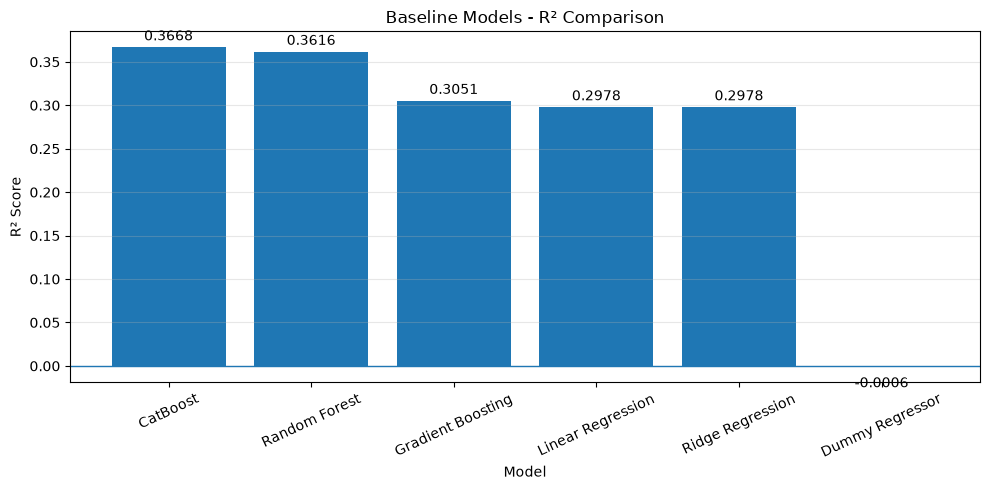

Updated R² comparison chart saved successfully.


In [18]:
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    baseline_results_df["Model"],
    baseline_results_df["R2"]
)

ax.axhline(0, linewidth=1)
ax.set_title("Baseline Models - R² Comparison")
ax.set_ylabel("R² Score")
ax.set_xlabel("Model")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.3)

for bar, score in zip(bars, baseline_results_df["R2"]):
    ax.annotate(
        f"{score:.4f}",
        (bar.get_x() + bar.get_width() / 2, score),
        xytext=(0, 5 if score >= 0 else -15),
        textcoords="offset points",
        ha="center"
    )

plt.tight_layout()
plt.savefig(
    os.path.join(FIGURES_DIR, "baseline_r2_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Updated R² comparison chart saved successfully.")

,Feature,Importance
0,city,9.6047
1,cuisine,9.6042
2,dominant_menu_category,8.9993
3,locality,5.4287
4,vegetarian_menu_ratio,4.9397
5,average_cost_for_two,4.6759
6,state,3.5619
7,menu_item_share_other,2.9334
8,top_menu_category_avg_price,2.7829
9,median_menu_item_price,2.6909


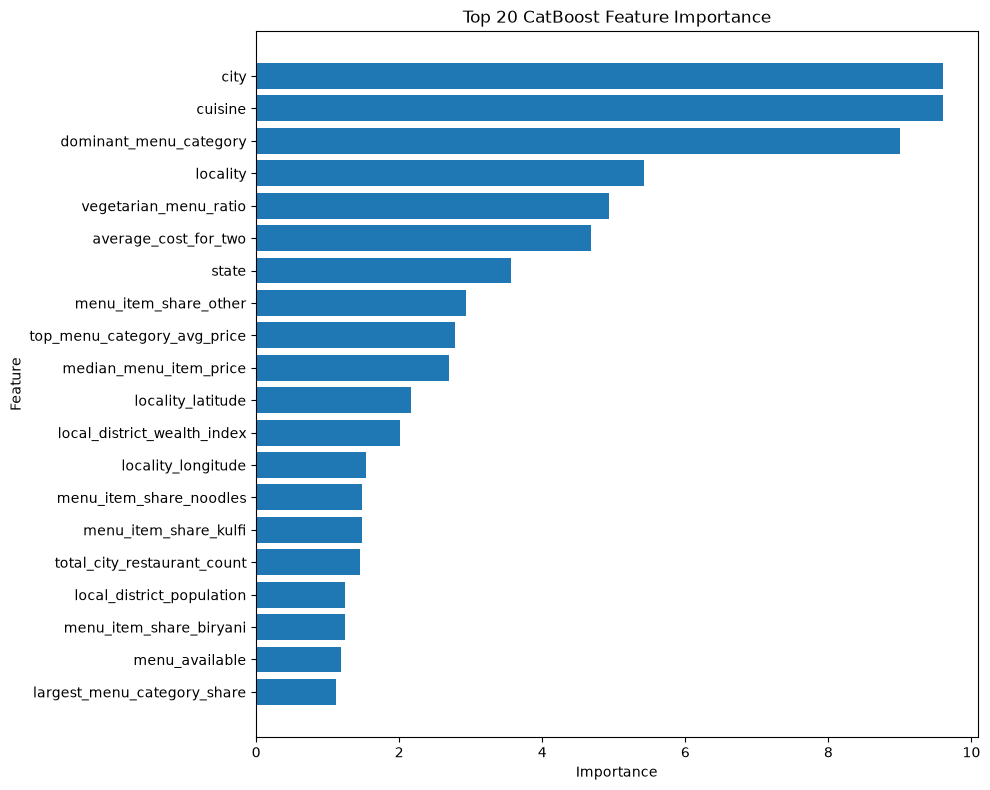

Feature importance table and chart saved successfully.


In [19]:
feature_importance_df = pd.DataFrame({
    "Feature": X_train_cat_base.columns,
    "Importance": catboost_model.get_feature_importance()
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

top_features = feature_importance_df.head(20)

display(
    top_features.style
    .format({"Importance": "{:.4f}"})
    .set_caption("Top 20 CatBoost Feature Importance")
)

feature_importance_df.to_csv(
    os.path.join(TABLES_DIR, "catboost_feature_importance.csv"),
    index=False
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title("Top 20 CatBoost Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_DIR, "catboost_feature_importance.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Feature importance table and chart saved successfully.")

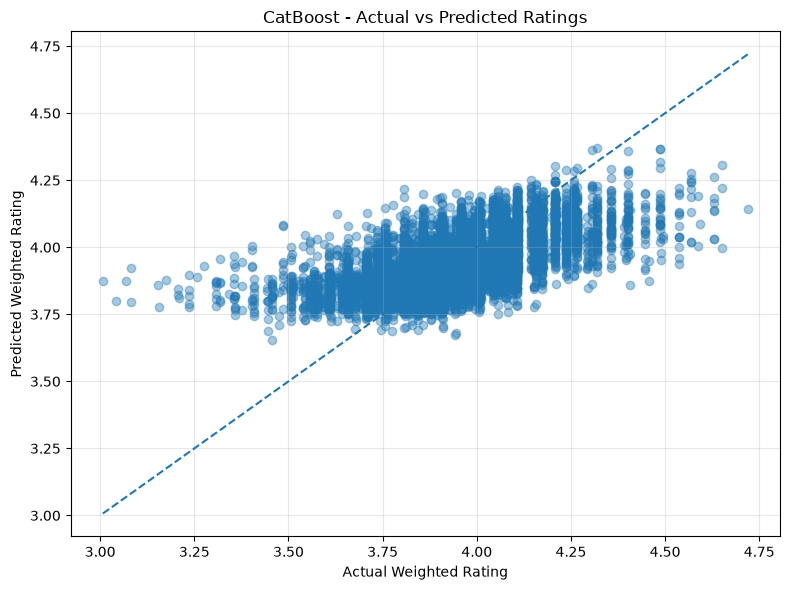

Actual vs predicted plot saved successfully.


In [20]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    y_val_base,
    catboost_val_predictions,
    alpha=0.4
)

min_value = min(y_val_base.min(), catboost_val_predictions.min())
max_value = max(y_val_base.max(), catboost_val_predictions.max())

ax.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

ax.set_title("CatBoost - Actual vs Predicted Ratings")
ax.set_xlabel("Actual Weighted Rating")
ax.set_ylabel("Predicted Weighted Rating")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(FIGURES_DIR, "catboost_actual_vs_predicted.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Actual vs predicted plot saved successfully.")

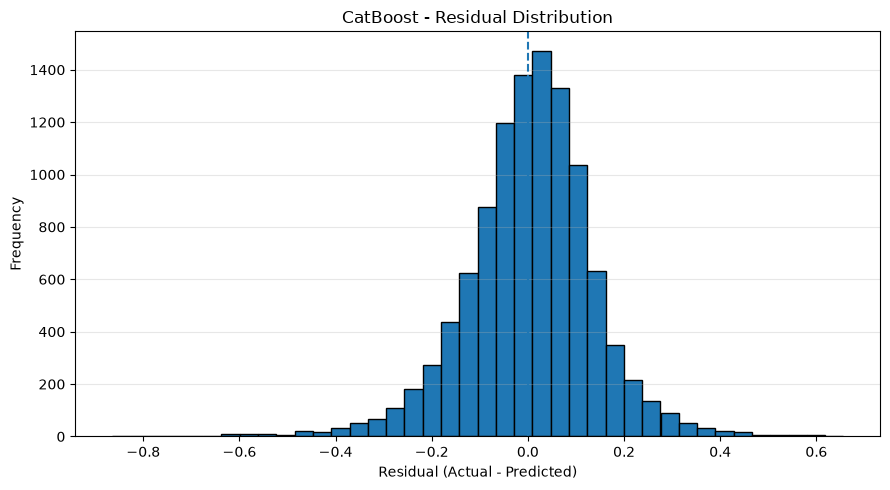

Residual distribution chart saved successfully.
Mean residual: 0.0044
Residual standard deviation: 0.13442


In [21]:
catboost_residuals = y_val_base - catboost_val_predictions

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    catboost_residuals,
    bins=40,
    edgecolor="black"
)

ax.axvline(0, linestyle="--")

ax.set_title("CatBoost - Residual Distribution")
ax.set_xlabel("Residual (Actual - Predicted)")
ax.set_ylabel("Frequency")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(FIGURES_DIR, "catboost_residual_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Residual distribution chart saved successfully.")
print("Mean residual:", round(catboost_residuals.mean(), 5))
print("Residual standard deviation:", round(catboost_residuals.std(), 5))

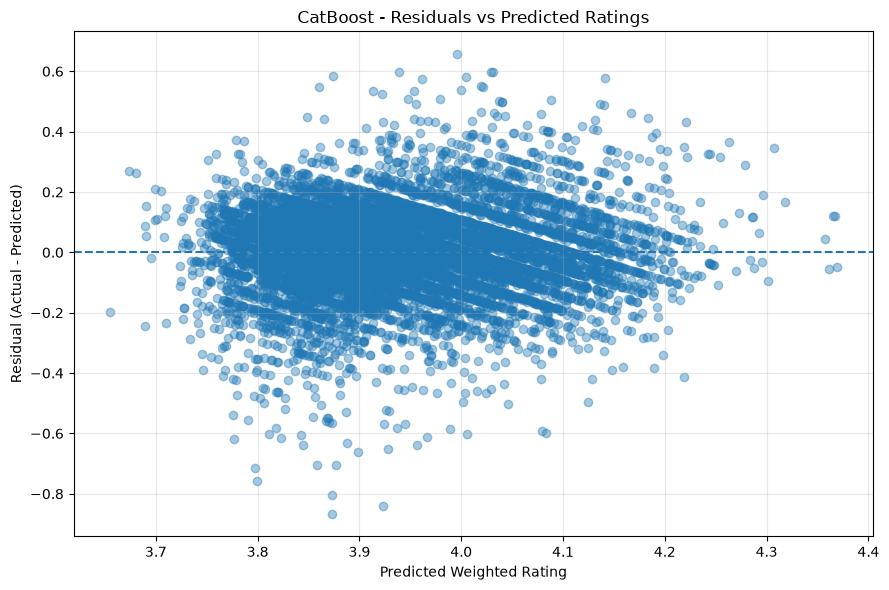

Residuals vs predicted chart saved successfully.


In [22]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    catboost_val_predictions,
    catboost_residuals,
    alpha=0.4
)

ax.axhline(0, linestyle="--")

ax.set_title("CatBoost - Residuals vs Predicted Ratings")
ax.set_xlabel("Predicted Weighted Rating")
ax.set_ylabel("Residual (Actual - Predicted)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(FIGURES_DIR, "catboost_residuals_vs_predicted.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Residuals vs predicted chart saved successfully.")

In [23]:
residual_analysis = pd.DataFrame({
    "Actual": y_val_base.values,
    "Predicted": catboost_val_predictions,
    "Residual": catboost_residuals.values
})

residual_analysis["Prediction_Range"] = pd.cut(
    residual_analysis["Predicted"],
    bins=5
)

residual_summary = residual_analysis.groupby(
    "Prediction_Range",
    observed=False
).agg(
    Count=("Residual", "count"),
    Mean_Residual=("Residual", "mean"),
    MAE=("Residual", lambda x: np.abs(x).mean()),
    RMSE=("Residual", lambda x: np.sqrt(np.mean(x ** 2)))
).reset_index()

display(
    residual_summary.style.format({
        "Mean_Residual": "{:.5f}",
        "MAE": "{:.5f}",
        "RMSE": "{:.5f}"
    }).set_caption("CatBoost Residual Analysis by Prediction Range")
)

residual_summary.to_csv(
    os.path.join(TABLES_DIR, "catboost_residual_summary.csv"),
    index=False
)

print("Residual summary saved successfully.")

,Prediction_Range,Count,Mean_Residual,MAE,RMSE
0,"(3.654, 3.798]",545,-0.00371,0.11530,0.14926
1,"(3.798, 3.941]",5646,0.00361,0.09363,0.12694
2,"(3.941, 4.083]",3531,0.00613,0.10375,0.13985
3,"(4.083, 4.226]",953,0.00472,0.11107,0.14734
4,"(4.226, 4.369]",40,0.06663,0.11408,0.15111


Residual summary saved successfully.



# 02. Baseline Model Training

## 1. Objective

The objective of this notebook is to establish baseline regression models for predicting restaurant `weighted_rating`.

Six regression algorithms were trained and evaluated using a separate validation dataset. Their performance was compared using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

## 2. Dataset Preparation

The preprocessed datasets generated in Notebook 01 were loaded.

| Dataset | Training Shape | Validation Shape |
|---|---:|---:|
| Processed Features | 42,859 × 263 | 10,715 × 263 |
| Scaled Features | 42,859 × 263 | 10,715 × 263 |
| CatBoost Features | 42,859 × 124 | 10,715 × 124 |

- The original training dataset was divided into 80% training and 20% validation.
- The original test dataset was kept untouched for final evaluation.
- Linear and Ridge Regression used scaled features.
- Random Forest and Gradient Boosting used processed, unscaled features.
- CatBoost used original categorical features without frequency encoding or scaling.

## 3. Models Trained

The following six regression models were trained:

1. Dummy Regressor
2. Linear Regression
3. Ridge Regression
4. Random Forest Regressor
5. Gradient Boosting Regressor
6. CatBoost Regressor

The Dummy Regressor was used as a reference model to establish a baseline performance.

## 4. Model Performance Comparison

Models were evaluated using MAE, RMSE, and R².

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| CatBoost | 0.09969 | 0.13448 | 0.36676 |
| Random Forest | 0.09980 | 0.13503 | 0.36157 |
| Gradient Boosting | 0.10362 | 0.14088 | 0.30511 |
| Linear Regression | 0.10483 | 0.14162 | 0.29777 |
| Ridge Regression | 0.10483 | 0.14162 | 0.29777 |
| Dummy Regressor | 0.12509 | 0.16905 | -0.00063 |

**Observation:** CatBoost achieved the best validation performance, with the lowest MAE and RMSE and the highest R² score.

## 5. Feature Importance Analysis

CatBoost feature importance was extracted to identify the most influential features.

The top five features were:

1. City
2. Cuisine
3. Dominant Menu Category
4. Locality
5. Vegetarian Menu Ratio

Other important features included average cost for two, state, menu-item price information, geographical coordinates, and local demographic indicators.

This suggests that geographical characteristics, cuisine, menu composition, and pricing contribute to the model's predictions.

Feature importance indicates predictive contribution, not causation.

## 6. Model Diagnostics

The best-performing baseline model, CatBoost, was further examined using:

- Actual vs Predicted Ratings Plot
- Residual Distribution Plot
- Residuals vs Predicted Ratings Plot
- Residual Analysis by Prediction Range

### Key Findings

- Mean residual: 0.0044
- Residual standard deviation: 0.13442
- The model performs better around the middle prediction range.
- Predictions tend to be closer to the average rating.
- Some larger prediction errors remain, particularly toward the prediction extremes.

## 7. Model Saving

All six trained baseline models were saved for future use.

The model files are stored in:

`outputs/baseline/models/`

The baseline comparison table is stored in:

`outputs/baseline/tables/`

The figures and diagnostic plots are stored in:

`outputs/baseline/figures/`

## 8. Conclusion

Six regression models were successfully trained and compared.

CatBoost achieved the best baseline validation performance:

- MAE: 0.09969
- RMSE: 0.13448
- R²: 0.36676

Random Forest achieved very similar performance and is another promising candidate.

CatBoost is selected as the leading candidate for the next phase, but it is not yet declared the final model.

## 9. Next Steps

The next notebook, `03_Model_Tuning_Evaluation.ipynb`, will focus on:

1. Hyperparameter tuning of promising models.
2. Comparing tuned models against baseline performance.
3. Selecting the best-performing model using validation results.
4. Evaluating the selected model on the untouched test dataset.
5. Saving the final model for deployment.
